# Publication registration benchmark: Allen MERFISH and BARseq

Self-contained entry point: run from a fresh kernel, top to bottom. No other notebook or existing model checkpoint is required. Repository Python modules are used for the methods; missing fits are trained here. This clone preserves the standardized experiment and accepted compact A-G figure.

**Before running:** follow [setup and data instructions](../docs/registration_reproduction.md), configure `.env`, and run `scripts/download_registration_allen.py` and `scripts/download_barseq_pilot.py`. Select the environment containing CAST, PASTE, DGL, and spatsplat. The complete run has 34 cases and eight methods (272 score rows).

The notebook runs data preparation, frozen-field reconstruction/registration, common evaluation, and the final figure. Optional summaries and the expanded cosine supplement are off by default. Fits can be expensive. Existing compatible fit caches are reused, but are not prerequisites. The data directory is local to each user; all figures go to root `figures/`, and checkpoints to `notebooks/checkpoints/`.

See [methods, experiments, and metrics](../docs/splat_registration_methods_and_experiments.md) and the [exact commit file list](../docs/registration_publication_files.txt).


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import torch
from dotenv import load_dotenv
from IPython.display import display
ROOT=Path.cwd().resolve()
while not ((ROOT/'pyproject.toml').exists() and (ROOT/'paper').is_dir()):
    if ROOT==ROOT.parent: raise RuntimeError('Repository root not found')
    ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
load_dotenv(ROOT/'.env')
from paper.dlpfc_splat_engine import ENGINE_DEFAULTS
from paper.dlpfc_registration import versions, pair_key
from paper.data_loaders.allen_registration import load_registration_sections
from paper.data_loaders.barseq_pilot import load_barseq_pilot
from paper.workflows.standardized_registration import (
    FAMILY_METHODS,source_signature,allen_cases,barseq_cases,run_cases)
from paper.workflows.standardized_rigid import (
    METHODS, DEFAULTS as RIGID_DEFAULTS, signature as rigid_signature, add_rigid, evaluate_cases)

SEED=1023
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
ALLEN_PAIRS=(('development',24,25),('evaluation',28,29),('evaluation',32,33))
BARSEQ_SECTIONS=(19,15,23,27)
ALLEN_MAXIMUM=3000
BARSEQ_MAXIMUM=8000
RUN={family:True for family in FAMILY_METHODS}
RUN_DIAGNOSTIC_FIGURES=False
RUN_SPLAT_RIGID=True
RIGID_SETTINGS=dict(RIGID_DEFAULTS, seed=SEED)
OPTIONS={
    'Geometry':dict(iterations=100),
    'PASTE':dict(alpha=.1,iterations=400,inner_iterations=1000000,gpu=False,seed=SEED),
    'CAST':dict(mark_epochs=400,affine_iterations=1500,ffd_iterations=800,gpu=False,
        seed=SEED,coordinate_scale=1000.,affine_step_multiplier=.1,ffd_step_size=5.,
        affine_diff_step=50.,ffd_diff_step=5.),
    'Splat':dict(ae_epochs=150,min_steps=1500,seed=SEED,device=DEVICE,
        engine_options={**ENGINE_DEFAULTS,
            'splat_config':dict(num_splats=512,latent_dim=32,hidden_dim=128,init_log_scale=-4.5,kernel_sharpness=.5),
            'section_splat_batch_size':512,'registration_query_count':2048,
            'nonaffine_grid_size':8,'nonaffine_displacement_weight':10.,'nonaffine_splat_match_weight':1.})}
SIGNATURE=source_signature(ROOT)
CONFIG=dict(seed=SEED,device=DEVICE,options=OPTIONS,versions=versions(),methods=METHODS,
    allen_pairs=ALLEN_PAIRS,barseq_sections=BARSEQ_SECTIONS,
    allen_maximum=ALLEN_MAXIMUM,barseq_maximum=BARSEQ_MAXIMUM,source_signature=SIGNATURE,
    rigid_settings=RIGID_SETTINGS,rigid_signature=rigid_signature(ROOT))
pd.options.display.float_format='{:.4g}'.format
display(pd.DataFrame([dict(family=f,outputs=', '.join(FAMILY_METHODS[f]),settings=json.dumps(OPTIONS[f])) for f in FAMILY_METHODS]))
print('One configuration per family for all tasks. Splat device:',DEVICE,'; CAST/PASTE: CPU')
print('RUN enables missing fits. New standardized caches do not overwrite historical fits.')

,family,outputs,settings
0,Geometry,Geometry rigid ICP,"{""iterations"": 100}"
1,PASTE,PASTE rigid,"{""alpha"": 0.1, ""iterations"": 400, ""inner_itera..."
2,CAST,"CAST affine, CAST non-affine","{""mark_epochs"": 400, ""affine_iterations"": 1500..."
3,Splat,"Splat affine, Splat non-affine","{""ae_epochs"": 150, ""min_steps"": 1500, ""seed"": ..."


One configuration per family for all tasks. Splat device: cuda ; CAST/PASTE: CPU
RUN enables missing fits. New standardized caches do not overwrite historical fits.


## Check dependencies and data paths
No fitting or downloads are performed in this check.

In [2]:
import importlib, importlib.metadata, os, platform

missing = []
for module in ('CAST', 'dgl', 'paste', 'ot', 'abc_atlas_access', 'anndata', 'matplotlib'):
    try:
        importlib.import_module(module)
    except Exception as exc:
        missing.append(f'{module}: {type(exc).__name__}: {exc}')
if missing:
    raise RuntimeError('Registration dependencies failed to import. See requirements-registration.txt:\n' + '\n'.join(missing))
base = os.getenv('SPATSPLAT_DATA_DIR')
if not base or base == '/path/to/spatsplat/data':
    raise RuntimeError('Copy .env.example to .env and set an absolute SPATSPLAT_DATA_DIR.')
DATA_ROOT = Path(base).expanduser()
ATLAS_ROOT = Path(os.getenv('SPATSPLAT_ABC_ATLAS_DIR', str(DATA_ROOT/'raw/abc_atlas'))).expanduser()
if not DATA_ROOT.is_absolute() or not ATLAS_ROOT.is_absolute():
    raise ValueError('Use absolute data/cache paths to avoid working-directory-dependent results.')
os.environ['SPATSPLAT_DATA_DIR'] = str(DATA_ROOT)
os.environ['SPATSPLAT_ABC_ATLAS_DIR'] = str(ATLAS_ROOT)
from paper.data_loaders.barseq_pilot import FILENAME
if not (DATA_ROOT/'raw/barseq_pilot'/FILENAME).is_file():
    raise FileNotFoundError('Run python scripts/download_barseq_pilot.py before continuing.')
if not ATLAS_ROOT.exists():
    raise FileNotFoundError('Run python scripts/download_registration_allen.py before continuing.')
COMMIT_MANIFEST = ROOT/'docs/registration_publication_files.txt'
required_files = [line.strip() for line in COMMIT_MANIFEST.read_text().splitlines()
                  if line.strip() and not line.startswith('#')]
absent = [name for name in required_files if not (ROOT/name).is_file()]
if absent:
    raise FileNotFoundError('Incomplete repository checkout: ' + ', '.join(absent))
print('Data directory:', DATA_ROOT)
print('Allen cache:', ATLAS_ROOT)
print('Splat device:', DEVICE, '; CAST and PASTE: CPU')


Data directory: /data/spatsplat-registration/data
Allen cache: /data/spatsplat-registration/data/raw/abc_atlas
Splat device: cuda ; CAST and PASTE: CPU


## Prepare cases without using evaluation targets in fitting
The Allen sample cap, coordinate normalization, real pairs, and combined perturbation are unchanged. The smooth control already includes 20-degree rotation, translation, and sinusoidal displacement; no separate rigid-only case is included. Its reference and query share expression/identities, making it an optimistic control.

BARseq recreates the original 8000-parent-measurement sampling and disjoint acquisitions. Keeping 100%, 80%, or 60% per view gives 100%, 60%, or 20% shared parent coverage. Crop axes are 0, 60, and 120 degrees; the query receives 35-degree rotation plus translation. Assignment to training/validation/test precedes cropping. In this standardized procedure, only the training subset is passed to **every** fitter; the original validation subset is reserved but unused. Internal AE validation and field checkpointing use only supplied training observations, matching the Allen fitting implementation. Test expression, true overlap, annotations, and true transforms never enter a fitter.

In [3]:
allen=load_registration_sections(sorted({s for _,a,b in ALLEN_PAIRS for s in (a,b)}),
    maximum=ALLEN_MAXIMUM,seed=SEED)
for _,a,b in ALLEN_PAIRS:
    if not np.isclose(allen['blocks'][b]['z']-allen['blocks'][a]['z'],.2):
        raise ValueError(f'Unexpected Allen slice gap {a}/{b}')
cases=allen_cases(allen,ALLEN_PAIRS)
barseq=load_barseq_pilot()
cases+=barseq_cases(barseq,BARSEQ_SECTIONS,maximum=BARSEQ_MAXIMUM,seed=SEED)
del allen,barseq
inventory=pd.DataFrame([dict(case=c['name'],dataset=c['dataset'],task=c['task'],role=c['role'],
    reference_fit=len(c['pair']['xy'][0]),query_fit=len(c['pair']['xy'][1]),
    reference_evaluated=len(c['reference_eval']),query_evaluated=len(c['query_eval']),
    retained_fraction=c['retained_fraction'],shared_fraction=c['shared_fraction'],direction=c['direction'],
    evaluation_design=c['evaluation_design']) for c in cases])
digest=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode())
for c in cases:
    digest.update(c['name'].encode()); digest.update(pair_key(c['pair'],{}).encode())
    for value in (c['reference_xy'],c['query_xy'],c['reference_values'],c['query_values'],
                  c['reference_eval'],c['query_eval'],c['truth']):
        if value is not None:
            value=np.ascontiguousarray(value)
            digest.update(str((value.shape,value.dtype)).encode()); digest.update(value.tobytes())
    if c['labels'] is not None:
        for value in c['labels']: digest.update(np.ascontiguousarray(value).tobytes())
ID=digest.hexdigest()[:20]
OUTPUT=ROOT/'notebooks/checkpoints/registration_publication_reproducible/reports'/ID
FIGURES=ROOT/'figures/registration_publication_reproducible'/ID
OUTPUT.mkdir(parents=True,exist_ok=True)
(OUTPUT/'protocol.json').write_text(json.dumps(CONFIG,indent=2))
inventory.to_csv(OUTPUT/'case_inventory.csv',index=False)
display(inventory)
print('Standardized report:',OUTPUT)
print('Expected:',len(cases),'cases x',len(METHODS),'methods =',len(cases)*len(METHODS),'rows')
manifest_record = ATLAS_ROOT/'_manifest_last_used.txt'
provenance = dict(python=platform.python_version(), platform=platform.platform(),
    versions=versions(), data_root=str(DATA_ROOT), atlas_root=str(ATLAS_ROOT),
    atlas_manifest=manifest_record.read_text().strip() if manifest_record.exists() else None,
    barseq_source=str(DATA_ROOT/'raw/barseq_pilot'/FILENAME),
    source_signature=SIGNATURE, rigid_signature=rigid_signature(ROOT),
    figure_source_sha256=hashlib.sha256((ROOT/'paper/workflows/standardized_publication.py').read_bytes()).hexdigest())
for distribution in ('abc_atlas_access','CAST'):
    provenance[distribution+'_direct_url'] = importlib.metadata.distribution(distribution).read_text('direct_url.json')
(OUTPUT/'data_environment_provenance.json').write_text(json.dumps(provenance, indent=2))


,case,dataset,task,role,reference_fit,query_fit,reference_evaluated,query_evaluated,retained_fraction,shared_fraction,direction,evaluation_design
0,allen_24_25_natural,Allen,natural,development,3000,3000,3000,3000,1,1,0,transductive; annotations and true transform w...
1,allen_24_25_combined_distortion,Allen,combined_distortion,development,3000,3000,3000,3000,1,1,0,transductive; annotations and true transform w...
2,allen_28_29_natural,Allen,natural,evaluation,3000,3000,3000,3000,1,1,0,transductive; annotations and true transform w...
3,allen_28_29_combined_distortion,Allen,combined_distortion,evaluation,3000,3000,3000,3000,1,1,0,transductive; annotations and true transform w...
4,allen_32_33_natural,Allen,natural,evaluation,3000,3000,3000,3000,1,1,0,transductive; annotations and true transform w...
5,allen_32_33_combined_distortion,Allen,combined_distortion,evaluation,3000,3000,3000,3000,1,1,0,transductive; annotations and true transform w...
6,barseq_19_keep_1_direction_0,BARseq,unequal_coverage,initial,2400,2400,800,800,1,1,0,held-out disjoint acquisitions; train only; re...
7,barseq_19_keep_0.8_direction_0,BARseq,unequal_coverage,initial,1930,1913,490,463,0.8,0.6,0,held-out disjoint acquisitions; train only; re...
8,barseq_19_keep_0.8_direction_60,BARseq,unequal_coverage,initial,1929,1946,471,490,0.8,0.6,60,held-out disjoint acquisitions; train only; re...
9,barseq_19_keep_0.8_direction_120,BARseq,unequal_coverage,initial,1947,1963,448,473,0.8,0.6,120,held-out disjoint acquisitions; train only; re...


Standardized report: /home/javeda/Documents/Research/spatsplat-registration/notebooks/checkpoints/registration_publication_reproducible/reports/993b521d4437863f28d2
Expected: 34 cases x 8 methods = 272 rows


1314

## Fit the common method roster
All splat fits call the same existing affine/non-affine engine. Non-affine refinement follows affine registration with fixed regularization/support settings. Geometry calls the same four-start rigid ICP. PASTE uses the corrected local solver. CAST uses the existing native Mark/Stack fitting body and checkpoint rule, extended only to save selected affine parameters and the sequence of native FFD meshes.

Held-out BARseq locations are evaluated with those saved transformations, **not interpolation of training-point displacements**. Splat affine/grid inverses are replayed with the engine's inverse settings. CAST uses its official spline coordinate operators, including its native boundary handling. Replay must reproduce the training mappings within a numerical tolerance before a fit is accepted. The out-of-sample readout sees coordinates only.

Missing or failed families remain explicit, with no unregistered fallback. Successful stages are cached. This is a new benchmark namespace: earlier BARseq rigid fields are not reused as if they were affine fields. All seven results are retained, including unfavorable refinements. Training and method-native plots run only when you execute this cell with enabled RUN flags.

**Splat rigid** restores the exact saved AE and fields from each standardized Splat fit. It fits only rotation and translation using symmetric decoded-profile cosine (12 initial angles, top 3 refined for 300 steps). Pose selection uses fitting coordinates only, never held-out expression. This shares fields, but not optimizer/objective details, with affine/non-affine registration, so it is a practical method comparison rather than a pure degrees-of-freedom ablation. Existing seven-method fit caches are reused; only missing rigid registrations are fitted. `RUN_SPLAT_RIGID=False` requires completed rigid caches.


In [4]:
fitted,status=run_cases(cases,OPTIONS,ROOT,OUTPUT,RUN,SIGNATURE)
fitted,status=add_rigid(cases,fitted,status,OPTIONS['Splat'],ROOT,OUTPUT,
    RIGID_SETTINGS,run=RUN_SPLAT_RIGID)
display(status)
display(status.groupby(['dataset','task','family','status']).size().rename('cases'))
status.to_csv(OUTPUT/'all_fit_status.csv',index=False)


Loaded Geometry: d86b1cee2c8bb8927c92
Loaded PASTE: aceb932ca6ec91dc50c4
Loaded CAST: 1a08d43b58a235f58f49


/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Loaded Splat: f1583e8b3572e8959a65
Loaded Geometry: 81b79ac438530eb2ffae
Loaded PASTE: 52cb0fdf42bdc4474cb3
Loaded CAST: 640a8acbaac01eb2a27a
Loaded Splat: ba0d7279fe4a876459fd
Loaded Geometry: b930505ca6ae78b2a92c
Loaded PASTE: 294fc30977343f9072ba
Loaded CAST: 2bdbc7a0ecc4c4584ce8
Loaded Splat: 3592ff5651a0d9022231
Loaded Geometry: 76f9e1eb0f23b2fb4710
Loaded PASTE: 001e921deda0bb6268fa
Loaded CAST: e4e1816bf0c64f45cc9e
Loaded Splat: 2446884a41033f43ab20
Loaded Geometry: a5aff1d5add4049867d5
Loaded PASTE: c6c452bfd9a4bb713e82
Loaded CAST: 93a7fc7462c722cc9d93
Loaded Splat: cda70145edb904fa1964
Loaded Geometry: 1ae5bb0f3740a302bd69
Loaded PASTE: e94bc9c83764a07eaa1b
Loaded CAST: 1008aac308399cafe5f7
Loaded Splat: e35c61e23f2b457fd722
Loaded Geometry: 73abae456dc3594dd67c
Loaded PASTE: 4e94720410a6484e2027
Loaded CAST: bc70b75c16b1162cfeec
Loaded Splat: 4766852e4851206069e1
Loaded Geometry: 9acc18a86950d2468e32
Loaded PASTE: b8402d4567205755d2ac
Loaded CAST: 41b341e93f95568f0735
Loaded

,case,dataset,task,family,status,cache
0,allen_24_25_natural,Allen,natural,Geometry,available,/home/javeda/Documents/Research/spatsplat-regi...
1,allen_24_25_natural,Allen,natural,PASTE,available,/home/javeda/Documents/Research/spatsplat-regi...
2,allen_24_25_natural,Allen,natural,CAST,available,/home/javeda/Documents/Research/spatsplat-regi...
3,allen_24_25_natural,Allen,natural,Splat,available,/home/javeda/Documents/Research/spatsplat-regi...
4,allen_24_25_combined_distortion,Allen,combined_distortion,Geometry,available,/home/javeda/Documents/Research/spatsplat-regi...
...,...,...,...,...,...,...
165,barseq_27_keep_0.8_direction_60,BARseq,unequal_coverage,Splat rigid,available,/home/javeda/Documents/Research/spatsplat-regi...
166,barseq_27_keep_0.8_direction_120,BARseq,unequal_coverage,Splat rigid,available,/home/javeda/Documents/Research/spatsplat-regi...
167,barseq_27_keep_0.6_direction_0,BARseq,unequal_coverage,Splat rigid,available,/home/javeda/Documents/Research/spatsplat-regi...
168,barseq_27_keep_0.6_direction_60,BARseq,unequal_coverage,Splat rigid,available,/home/javeda/Documents/Research/spatsplat-regi...


dataset  task                 family       status   
Allen    combined_distortion  CAST         available     3
                              Geometry     available     3
                              PASTE        available     3
                              Splat        available     3
                              Splat rigid  available     3
         natural              CAST         available     3
                              Geometry     available     3
                              PASTE        available     3
                              Splat        available     3
                              Splat rigid  available     3
BARseq   unequal_coverage     CAST         available    28
                              Geometry     available    28
                              PASTE        available    28
                              Splat        available    28
                              Splat rigid  available    28
Name: cases, dtype: int64

## Evaluate without selecting by test results
Allen natural alignment: common spatial-transport CCF division and exact-label agreement, with unknown labels excluded from scored mass; observed-expression cosine is descriptive/transductive. Allen controlled recovery: known-transform error in reference-neighbor spacings. BARseq coverage: the same positional error evaluated on held-out query observations inside the true shared region, plus symmetric radius-limited five-neighbor expression transfer using held-out observations from both views.

Coverage-weighted cosine assigns zero to unsupported observations. Positional accuracy is `1/(1 + median normalized positional error)`. These numerical endpoints are not pooled between datasets. Triangle orientation/collapse and spline inverse diagnostics are retained as quality checks, not silently used to remove unfavorable results. Rigid-only methods cannot completely undo a nonlinear distortion; standard balanced PASTE is not a partial-overlap algorithm.

In [5]:
scores,availability=evaluate_cases(cases,fitted,OUTPUT,permutations=99,seed=SEED)
display(availability.groupby('method').available.agg(['sum','count']))
display(scores.groupby(['dataset','task','role','method'])[
    ['coverage_weighted_cosine','median_error_neighbor_spacings','local_fold_fraction']].median())
complete=bool(len(availability)==len(cases)*len(METHODS) and availability.available.all())
(OUTPUT/'completion.json').write_text(json.dumps(dict(complete=complete,expected=len(cases)*len(METHODS),
    available=int(availability.available.sum()),protocol_id=ID),indent=2))
print('Complete method matrix:',complete)
if not complete: print('Review fit_status.csv; missing methods must remain visible in comparisons.')

,sum,count
method,,
CAST affine,34,34
CAST non-affine,34,34
Geometry rigid ICP,34,34
PASTE rigid,34,34
Splat affine,34,34
Splat non-affine,34,34
Splat rigid,34,34
Unregistered,34,34


coverage_weighted_cosine  \
dataset task                role        method                                         
Allen   combined_distortion development CAST affine                           0.4166   
                                        CAST non-affine                        0.839   
                                        Geometry rigid ICP                    0.5248   
                                        PASTE rigid                           0.6042   
                                        Splat affine                          0.8583   
                                        Splat non-affine                      0.8362   
                                        Splat rigid                           0.5509   
                                        Unregistered                          0.3505   
                            evaluation  CAST affine                           0.4534   
                                        CAST non-affine                       0.8859   
                                        Geometry rigid ICP                    0.5739   
                                        PASTE rigid                           0.6261   
                                        Splat affine                          0.9128   
                                        Splat non-affine                      0.8643   
                                        Splat rigid                           0.6203   
                                        Unregistered                          0.3913   
        natural             development CAST affine                           0.5055   
                                        CAST non-affine                       0.5158   
                                        Geometry rigid ICP                    0.4821   
                                        PASTE rigid                           0.4629   
                                        Splat affine                          0.5232   
                                        Splat non-affine                      0.5205   
                                        Splat rigid                           0.5017   
                                        Unregistered                           0.488   
                            evaluation  CAST affine                           0.5079   
                                        CAST non-affine                       0.5336   
                                        Geometry rigid ICP                    0.5053   
                                        PASTE rigid                           0.4848   
                                        Splat affine                          0.5358   
                                        Splat non-affine                      0.5315   
                                        Splat rigid                           0.5088   
                                        Unregistered                          0.5125   
BARseq  unequal_coverage    evaluation  CAST affine                           0.2025   
                                        CAST non-affine                       0.3276   
                                        Geometry rigid ICP                    0.2222   
                                        PASTE rigid                           0.2218   
                                        Splat affine                          0.4024   
                                        Splat non-affine                      0.4212   
                                        Splat rigid                           0.5406   
                                        Unregistered                          0.1233   
                            initial     CAST affine                           0.1477   
                                        CAST non-affine                       0.3169   
                                        Geometry rigid ICP                     0.279   
                                        PASTE rigid                           0.1383   
            

Complete method matrix: True


## Optional diagnostic summaries
Disabled by default. Set `RUN_DIAGNOSTIC_FIGURES=True` in setup to include them.

In [6]:
if RUN_DIAGNOSTIC_FIGURES:
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    FIGURES.mkdir(parents=True,exist_ok=True)
    colors={m:plt.get_cmap('tab10')(i) for i,m in enumerate(METHODS)}
    def export(fig,name):
        for ext in ('png','pdf'): fig.savefig(FIGURES/f'{name}.{ext}',bbox_inches='tight',dpi=180)
        plt.show(); plt.close(fig)
    if not complete: raise RuntimeError('Complete the method matrix before generating summary figures')
    fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
    for ax,task,metric in zip(axes,['natural','combined_distortion'],['ccf_division_agreement','positional_accuracy']):
        for j,(section,marker) in enumerate(((28,'o'),(32,'D'))):
            g=scores[(scores.dataset=='Allen')&(scores.task==task)&(scores.section==section)].set_index('method').loc[list(METHODS)]
            ax.scatter(g[metric],np.arange(len(METHODS))+(j-.5)*.2,c=[colors[m] for m in METHODS],marker=marker,label=f'Section {section}')
        ax.set_yticks(range(len(METHODS)),METHODS); ax.invert_yaxis()
        limits=(-.02,1.02)
        if task=='natural':
            values=scores.loc[(scores.dataset=='Allen') & (scores.task==task) &
                scores.section.isin([28,32]) & scores.method.isin(METHODS),metric].to_numpy()
            values=values[np.isfinite(values)]
            limits=(.6,.8)
            if values.size:
                limits=(max(0.,min(.6,float(values.min())-.01)),
                        min(1.,max(.8,float(values.max())+.01)))
            from matplotlib.ticker import MultipleLocator, FormatStrFormatter
            ax.xaxis.set_major_locator(MultipleLocator(.05))
            ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
        ax.set(xlim=limits,title='Allen: '+task.replace('_',' '),xlabel=metric.replace('_',' ')); ax.legend()
    export(fig,'allen_standardized')
    fig,axes=plt.subplots(1,2,figsize=(15,5),layout='constrained')
    follow=scores[(scores.dataset=='BARseq')&(scores.role=='evaluation')]
    for ax,metric in zip(axes,['positional_accuracy','coverage_weighted_cosine']):
        for k,level in enumerate((1.,.6,.2)):
            for j,method in enumerate(METHODS):
                g=follow[(follow.method==method)&np.isclose(follow.shared_fraction,level)]
                x=k+(j-(len(METHODS)-1)/2)*.10
                ax.boxplot([g[metric].to_numpy()],positions=[x],widths=.08,manage_ticks=False,showfliers=False,
                    patch_artist=True,boxprops=dict(facecolor=colors[method],alpha=.3))
                ax.scatter(x+np.linspace(-.025,.025,len(g)),g[metric],s=12,c=[colors[method]])
        ax.set_xticks(range(3),['100 / 100','80 / 60','60 / 20'])
        ax.set(ylim=(-.02,1.02),xlabel='Retained % / shared %',ylabel=metric.replace('_',' '))
    fig.legend(handles=[Patch(facecolor=colors[m],label=m) for m in METHODS],loc='outside lower center',ncol=4,frameon=False)
    export(fig,'barseq_standardized')

## Final publication figure: measurement correspondences
This separate figure uses side-by-side sections connected by inferred measurement matches, in the style of the original non-affine anchor plot. Panels A/B show the natural Allen correspondence view and agreement metric; C/D show the controlled Allen correspondence view and recovery metric; E/F/G show BARseq before, after, and recovery. Both separated Allen slices use filled circles. BARseq overlays retain filled reference and hollow query markers. Cosine is omitted from this main figure; an expanded supplement is optional below.
Spatial axes retain their allocated grid rectangles, padding coordinate limits as needed while preserving equal x/y scale. The Allen panels therefore have matching widths, and the outer edges of the BARseq pair align beneath them.

Matches are mutual nearest neighbors between the reference and registered query coordinates, restricted to two median reference-neighbor spacings. There is no annotation, expression-similarity, or ground-truth filtering. A fixed-seed random subset of at most `MAX_MEASUREMENT_LINKS` pairs is drawn to avoid clutter; each panel reports shown and eligible counts. The subset is not selected for agreement or low error.

Both tissues are drawn in their original input geometry, with the query shifted horizontally for display only. Registration determines which measurements are linked. Lines therefore show inferred correspondence, not displacement vectors, error magnitudes, or training anchors. Adjacent physical sections have no verified one-to-one measurement identity. The same inference rule is also used for the controlled copy, without consulting its known identities. Unmatched measurements remain visible; the metric panels still use the full planned evaluation, not just these links.

Run this cell after evaluation; it does not fit models or change scores. `CORRESPONDENCE_EXAMPLE_METHOD` selects the same splat variant for both Allen examples and the BARseq after panel. This layout replaces before/after overlays with one inferred-match view, so use the retained original figure when explicit before/after comparison is needed.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


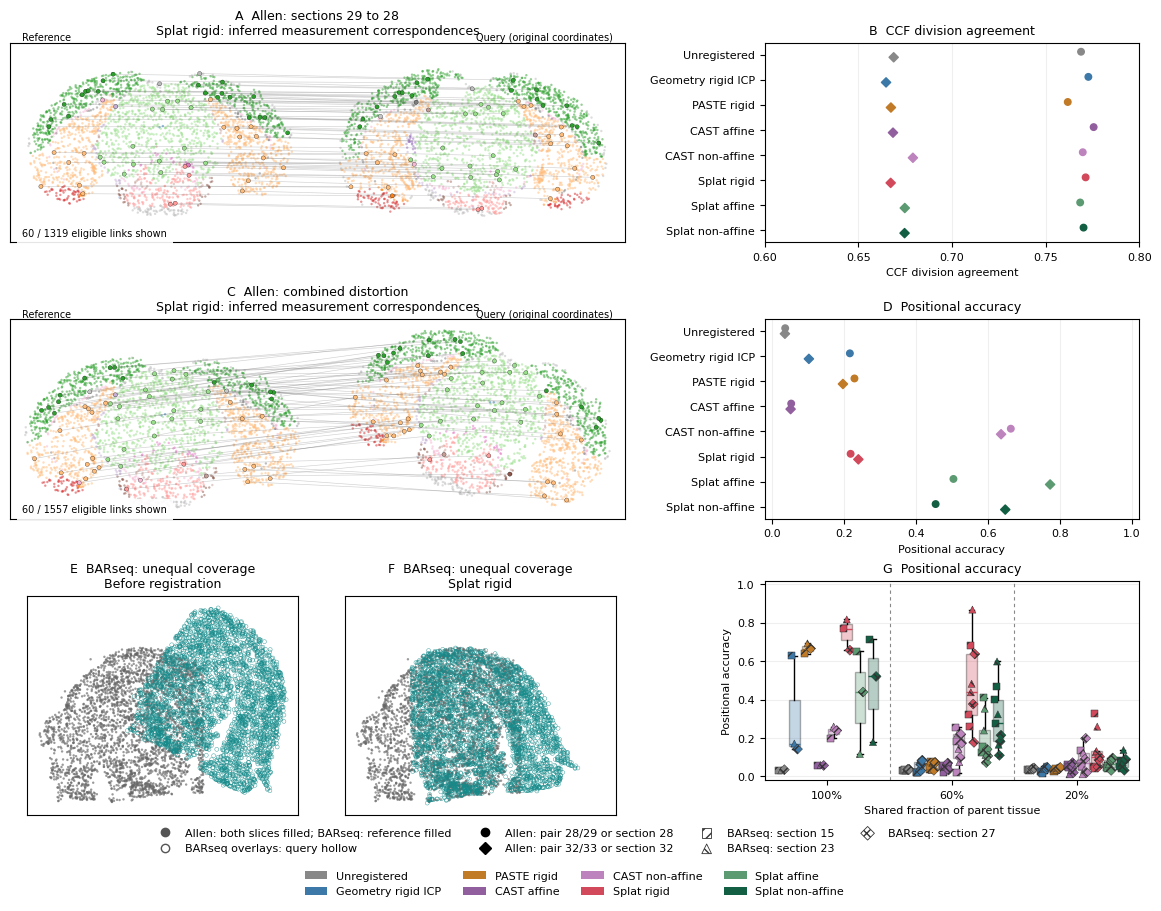

Correspondence figure saved to: /home/javeda/Documents/Research/spatsplat-registration/figures/registration_publication_reproducible/993b521d4437863f28d2


In [7]:
import importlib
from paper.workflows import standardized_publication
importlib.reload(standardized_publication)
import matplotlib.pyplot as plt

CORRESPONDENCE_EXAMPLE_METHOD = 'Splat rigid'
MAX_MEASUREMENT_LINKS = 60
if not complete:
    raise RuntimeError('Complete all eight methods before making the publication figure.')
correspondence_fig = standardized_publication.publication_figure(
    cases, fitted, scores, example_method=CORRESPONDENCE_EXAMPLE_METHOD,
    include_cosine=False, measurement_links=True, maximum_links=MAX_MEASUREMENT_LINKS)
FIGURES.mkdir(parents=True, exist_ok=True)
correspondence_stem = ('registration_publication_measurement_links_' +
    CORRESPONDENCE_EXAMPLE_METHOD.lower().replace(' ', '_'))
for extension in ('pdf', 'png'):
    correspondence_fig.savefig(FIGURES/f'{correspondence_stem}.{extension}',
        dpi=300, bbox_inches='tight')
plt.show()
plt.close(correspondence_fig)
print('Correspondence figure saved to:', FIGURES)


## Optional expanded supplement
The full before/after layout includes the coverage-weighted cosine panels and exports separately. Disabled by default.

In [8]:
MAKE_PUBLICATION_SUPPLEMENT = False
if MAKE_PUBLICATION_SUPPLEMENT:
    if not complete:
        raise RuntimeError('Complete all eight methods before exporting the supplement.')
    supplement_fig = standardized_publication.publication_figure(cases, fitted, scores,
        example_method=CORRESPONDENCE_EXAMPLE_METHOD, include_cosine=True)
    for extension in ('pdf', 'png'):
        supplement_fig.savefig(FIGURES/f'registration_publication_supplement_with_cosine.{extension}',
            dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(supplement_fig)
